In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("C:/Users/Admin/OneDrive/Documents/anaconda_projects/python datasets/Titanic-Dataset.csv")

# Understanding dataset structure:

- `Pclass` : shows the class like 1st class and second class.
- `Fare` : shows the cost for the ticket.
- `SibSp` : represents number of siblings on the board.
- `Parch` : represents number of elders like parents or children on the board.
- `Ticket` : shows the ticket number.

   ***Note :***

  `Parch` represents the vertical relationship like parents or childer or grandparents etc while on the other hand `SibSp` represents horizontal relationship like wife, husband, stepbrother, and sister etc.

  `Ticket`, although is supposed to be unique but its not unique for all passengers. This is because some passengers usually families shared the same ticket and thus there `Ticket` and their `Fare` both are same.

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
822,823,0,1,"Reuchlin, Jonkheer. John George",male,38.0,0,0,19972,0.0,NaN,S
481,482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0,NaN,S
586,587,0,2,"Jarvis, Mr. John Denzil",male,47.0,0,0,237565,15.0,NaN,S
539,540,1,1,"Frolicher, Miss. Hedwig Margaritha",female,22.0,0,2,13568,49.5,B39,C
298,299,1,1,"Saalfeld, Mr. Adolphe",male,NaN,0,0,19988,30.5,C106,S


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
shape = df.shape
print(f"Rows : {shape[0]}\nColumns : {shape[1]}")

Rows : 891
Columns : 12


In [7]:
integer_col = df.select_dtypes(include="integer").columns.tolist()
string_col = df.select_dtypes(include="object").columns.tolist()
float_col = df.select_dtypes(include="float").columns.tolist()
print(f"1. Integer columns : {integer_col}\n2. String columns : {string_col}\n3. Float columns : {float_col}")

1. Integer columns : ['PassengerId', 'Survived', 'Pclass', 'SibSp', 'Parch']
2. String columns : ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
3. Float columns : ['Age', 'Fare']


In [8]:
df['Cabin'].isnull().value_counts()

Cabin
True     687
False    204
Name: count, dtype: int64

In [9]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
df.notnull().sum()

PassengerId    891
Survived       891
Pclass         891
Name           891
Sex            891
Age            714
SibSp          891
Parch          891
Ticket         891
Fare           891
Cabin          204
Embarked       889
dtype: int64

In [11]:
print("Duplicated rows : ", df.duplicated().sum())

Duplicated rows :  0


In [12]:
# here 0 represents unsurvived and 1 represents the survived one
unique = df['Survived'].unique().tolist()
unique

[0, 1]

In [13]:
nunique = df.nunique() 
nunique, len(df.index)

(PassengerId    891
 Survived         2
 Pclass           3
 Name           891
 Sex              2
 Age             88
 SibSp            7
 Parch            7
 Ticket         681
 Fare           248
 Cabin          147
 Embarked         3
 dtype: int64,
 891)

In [14]:
nunique.max(), nunique.min()

(891, 2)

1. ***Columns with most and few unique values.***

We can see the `PassengerId` and `Name` are the columns with max unique values while the columns `Survived` and `Sex` contain min unique values that is 2.

2. ***Identifiers***
   
Thus its also clear that as we can see the total values in the columns are *891* similarly the unique values in columns `Name` and `PassengerId` are also *891* thus we can use these columns as *Identifiers*.

4. ***Categorical Columns***

Columns with very few unique values can be taken as categorical columns eg `Sex`, `Survived`, `Pclass` and `Embarked`.


# Statistical Analysis:

In [15]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**~Results~**:

Thus in above table we can see different info like *Average, Mininmum, Maximum Passenger age*, *Average, Minimum, Maximum Fare*, and *Median Age*.

In [16]:
missing_values = df.isnull().sum()
sorted_missings = missing_values[missing_values > 0].sort_values(ascending=False)
print(f"Column containg the largest number of null values ({sorted_missings.iloc[0]}) :", sorted_missings.index[0])

Column containg the largest number of null values (687) : Cabin


In [17]:
dictionary = {}
for col in df.columns:
    missings = df[col].isnull().sum()
    total = len(df.index)
    miss_percent = (missings/total)*100
    dictionary[col] = miss_percent.round(2)

for key in dictionary:
    print(f"Column name : {key}\t\tPerncetage Missing : {dictionary[key]} %")    

Column name : PassengerId		Perncetage Missing : 0.0 %
Column name : Survived		Perncetage Missing : 0.0 %
Column name : Pclass		Perncetage Missing : 0.0 %
Column name : Name		Perncetage Missing : 0.0 %
Column name : Sex		Perncetage Missing : 0.0 %
Column name : Age		Perncetage Missing : 19.87 %
Column name : SibSp		Perncetage Missing : 0.0 %
Column name : Parch		Perncetage Missing : 0.0 %
Column name : Ticket		Perncetage Missing : 0.0 %
Column name : Fare		Perncetage Missing : 0.0 %
Column name : Cabin		Perncetage Missing : 77.1 %
Column name : Embarked		Perncetage Missing : 0.22 %


***Conclusion***:

+ Column `Cabin` contains the most missing values that is upto **77.1%**. Thus filling these values wont make our calculations more effective because we only have upto *three forth* of the total data in this column which is insufficint.
+ Column `Age` contains the most number of misssing values on second number that is **19.87%** which is still a big part but its somehow coverable as compared to the missing values in `Cabin` column.
+ Column `Embarked` also contains some missing values but its just a fractional part as compared to total data in it. 

## Data Cleaning

In [18]:
df = df.drop_duplicates().copy()

In [19]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [20]:
df['Embarked'] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [21]:
df.isnull().sum()
# Confirming wether the data has been cleaned

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

## Group Analysis

In [22]:
survival_rate = df['Survived'].mean()*100
print(f"Overall Survival Rate: {survival_rate.round(2)}%")

Overall Survival Rate: 38.38%


Based on the historical events, you should expect to investigate questions like:

1. Did women survive more often than men?
2. Did first-class passengers survive more often than third-class passengers?
3. Did children have higher survival rates?
4. Does paying a higher fare correlate with better survival?
5. Did the embarkation port influence survival?
6. Did traveling with family improve or reduce survival chances?
7. Are certain titles (Mr., Mrs., Miss., Master.) associated with survival?
8. Are there patterns in cabin assignments and survival?

In [23]:
df.groupby(['Sex', 'Pclass'])[['Survived']].mean().round(3)

Survived
Sex    Pclass          
female 1          0.968
       2          0.921
       3          0.500
male   1          0.369
       2          0.157
       3          0.135

In [24]:
age_sur = df.groupby([np.where(df['Age']>18, 'Adult', 'Minor'),
                      'Pclass'])['Survived'].mean().round(3).unstack()
age_sur

Pclass,1,2,3
Adult,0.610,0.413,0.217
Minor,0.875,0.793,0.351


In [25]:
gen_sur = df.groupby(['Sex', 'Pclass'])['Survived'].mean().round(3).unstack()
gen_sur

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


In [26]:
sur_analysis = pd.concat([age_sur, gen_sur], axis=0)
sur_analysis.index

Index(['Adult', 'Minor', 'female', 'male'], dtype='object')

In [27]:
sur_analysis.index = pd.MultiIndex.from_arrays(
                            [['Age band', 'Age band', 'Gender','Gender'],
                            ['Minor', 'Adult', 'Female', 'Male']])

In [28]:
sur_analysis

Pclass               1      2      3
Age band Minor   0.610  0.413  0.217
         Adult   0.875  0.793  0.351
Gender   Female  0.968  0.921  0.500
         Male    0.369  0.157  0.135

In [29]:
emb_sur = df.groupby(['Embarked', 'Pclass'])['Survived'].aggregate('mean').round(3).unstack()
emb_sur

Pclass,1,2,3
Embarked,,,
C,0.694,0.529,0.379
Q,0.500,0.667,0.375
S,0.589,0.463,0.190


In [30]:
df["Family"] = df["Parch"] + df["SibSp"]

In [31]:
age = np.where(df["Age"]>18, 'Adult', 'Minor')
fare = pd.cut(df['Fare'], bins=2, labels=['Low', 'High'])
family = np.where(df["Family"] >0, "With Family", "Solo")

p_table = pd.pivot_table(df,
                values='Survived',
               index=['Sex', age, fare],
               columns=['Pclass', family],
              fill_value='_',
                observed = False)

p_table = p_table.style.format(precision=2)
# Generates a formatted pivot table showing survival rates (rounded to 2 decimals) 
# broken down by demographic factors (Sex, Age, Fare) and journey context (Pclass, Family status).

p_table 

C:\Users\Admin\AppData\Local\Temp\ipykernel_7896\2305003312.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  p_table = pd.pivot_table(df,


## Data visualization

In [32]:
numeric_cols = ["Age", "Fare", "SibSp", "Parch"]

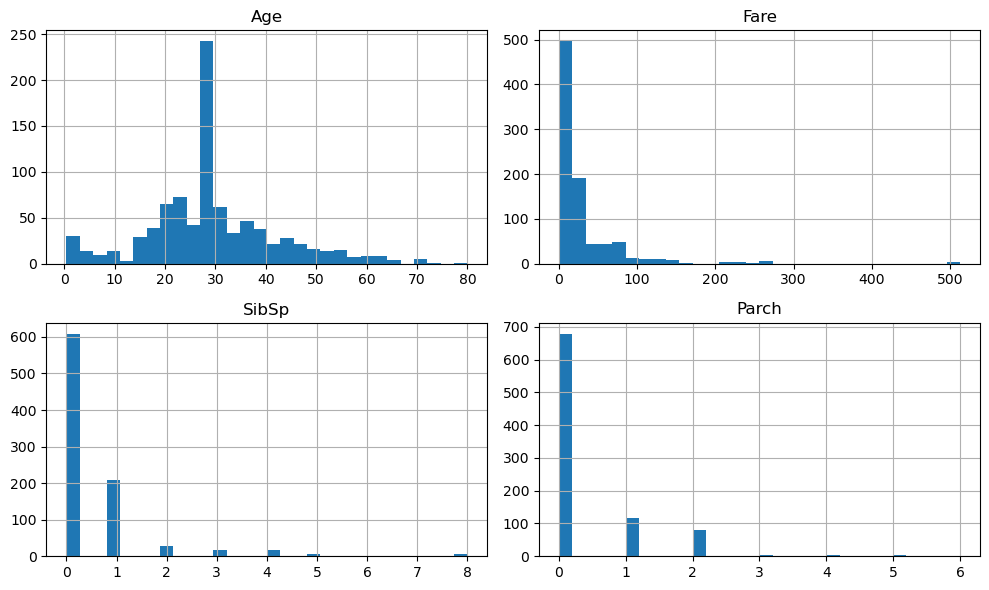

In [33]:
df[numeric_cols].hist(
bins=30,
figsize=(10, 6),
layout=(2, 2)
)
plt.tight_layout()
plt.show()

***Resluts***

+ Thus its confirmed that mostly the travellers on the boat were in the age between *25-30*.
+ Most travellers were travelling in low fare.
+ Majority of the travellers didn't travelled with there families.

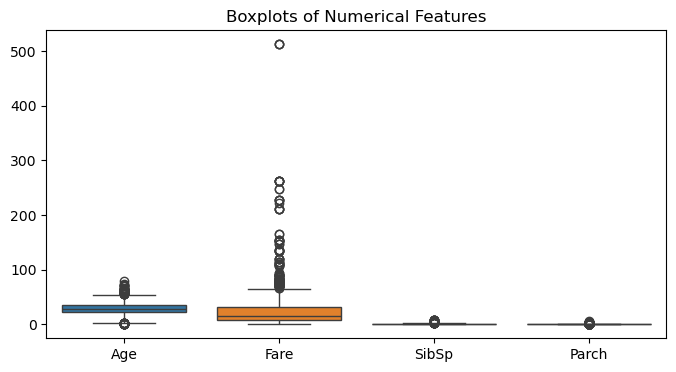

In [34]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df[numeric_cols])
plt.title("Boxplots of Numerical Features")

plt.show()

***Results***
+ Its confirmed that the column `Fare` has most outliers, others have almost none or very little outliers.
+ Seeing an outlier does not automatically means that the data is incorrect because in real world there do e

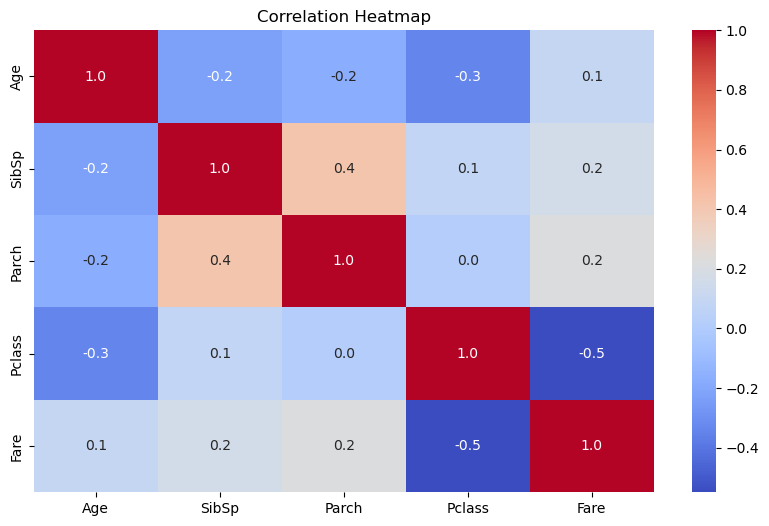

In [35]:
selected_cols = ["Age", "SibSp", "Parch", "Pclass", "Fare"]
plt.figure(figsize=(10, 6))

sns.heatmap(
df[["Age", "SibSp", "Parch", "Pclass", "Fare"]].corr(),
annot=True,
cmap="coolwarm",
fmt=".1f"
)
plt.title("Correlation Heatmap")
plt.show()

***Results***
+ This implies that there is a good *direct relation* between the columns `Parch` and `SibSp`.
+ There is a good *indirect relation* between the columns `Pclass` and `Fare` this is realistic as the more we pay the *fare* the more top *Pclass* we will be given that is 0, 1 this means that there is really an indirect realion.
+ There is almost no *relation* between `Fare` and `Parch` this can be as these are totally independent concepts.

  ***NOTE :***

  *Coorelation* does not confirm a true *Cause and Effect* relation infact it just shows how much two variables are changing relatinvely with respect to each other and nothing else this changing can be brought by any other third factor or any other column or hidden factor , but coorelation is not about *Cause and Effect*.

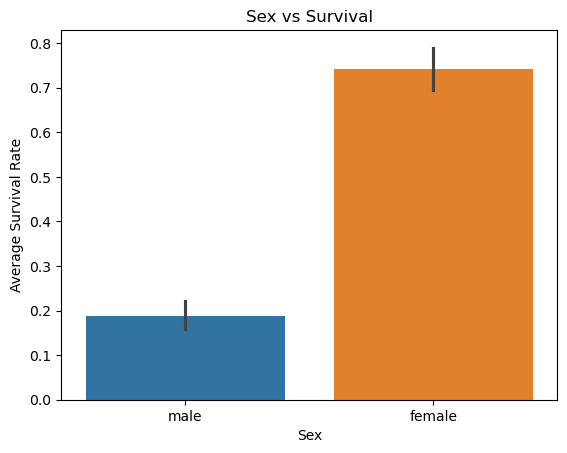

In [36]:
sns.barplot(
x="Sex",
y="Survived",
data=df,
hue="Sex",
legend=False
)
plt.title("Sex vs Survival")
plt.xlabel("Sex")
plt.ylabel("Average Survival Rate")
plt.show()


***Result*** 
+ This is clear that female survival rate is far more than men's this not becuase they are more strong but infact in real historical incident many passsengers prioritized to give pass ways to females and children because they are weak and need help in this way women and children survival rate is more high. 

In [51]:
topFares = df.sort_values(
by="Fare",
ascending=False
)
top5 = topFares.head(5)

top5[["Name", "Sex", "Pclass", "Fare"]]

,Name,Sex,Pclass,Fare
258,"Ward, Miss. Anna",female,1,512.3292
737,"Lesurer, Mr. Gustave J",male,1,512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",male,1,512.3292
88,"Fortune, Miss. Mabel Helen",female,1,263.0000
27,"Fortune, Mr. Charles Alexander",male,1,263.0000


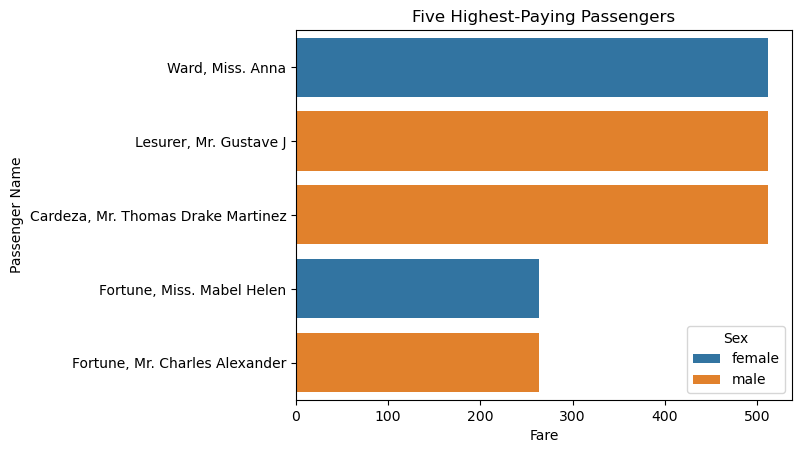

In [38]:
sns.barplot(
x="Fare",
y="Name",
data=top5,
hue="Sex"
)
plt.title("Five Highest-Paying Passengers")
plt.xlabel("Fare")
plt.ylabel("Passenger Name")
plt.show()

***Results*** 
+ Passengers named *Ward, Miss. Anna*, *Cardeza, Mr. Thomas Drake Martinez* and *Lesurer, Mr. Gustave J* paid the highest fare.
+ All the shown passengers paying high fare trvalled in high class that is *First class*.
+ These top high payers are actually paying far more than what majority is paying and are thus ~outliers~.

# Final EDA Answers

1. Total rows and coplumns : *891 rows and 13 columns*
2. In the begining there were 3 columns `Age`, `Cabin` and `Embarked` contained missing values but after cleaning data we only left with one column `Cabin` containing missing values that are in the percentage of more than *70%*.
3. Column `Cabin` contains the highest number of missing values of more than *70%*.
4. To fill the dmissing values in column `Age` we fill it with median of total ages present in the column and this is because its a numerical data and putting any random number will affect our analysis more than to put an average of all the values which will reduce the errors.
5. To fill the missing values in column `Embarked` we used the most repeated value in the column such that mode of all values in the column, beacuse this was not a numeric column thus we cant use any average, meanwhile this made our process of data cleaning more data dependent and far from irrelvant cleaning.

In [44]:
df['Survived'].mean()

0.3838383838383838

6. From above calculation we can see the overall survival rate is less than *50%*.
7. No there were no duplicated rows in the dataset.
8. Female survival rate is far more than men's, this is not becuase they are more strong but infact in real historical incident many passsengers prioritized to give pass ways to females and children because they are weak and need help in this way women and children survival rate is more high.

In [49]:
df.groupby(["Pclass"])[["Survived"]].aggregate("mean")

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


9. we can see that *Pclass* *1* survived the most and the survival rate for Pclass *3* if very less.
10. In boxplot we found that the column/ feature `Fare` contain the clearest ouliers.
11. From the graphs related to `Fare` we found that in ~Histogram~ and  ~boxplot~ we analyzed that majority of Passengers paid the Fare amount in between *0-50* but there were very few but clear outliers with ranging Fare amount above *500*.
12. From the ~heatmap graph~ we found that there is a good *indirect relation* between the columns `Pclass` and `Fare` this is realistic as the more we pay the *fare* the more top *Pclass* we will be given that is 0, 1 this means that there is really an indirect realion.
13. From ~bar graph~ we found that passengers named *'Ward, Miss. Anna', 'Lesurer, Mr. Gustave J', 'Cardeza, Mr. Thomas Drake Martinez', 'Fortune, Miss. Mabel Helen', 'Fortune, Mr. Charles Alexander'* paid the highest fare.

## Important Findings:
1. **Social class was a deciding factor in survival:** Passengers in first class (Pclass 1) had the highest survival rates due to upper-deck cabin locations and evacuation priority, while third-class passengers faced major physical and structural barriers to reaching lifeboats.
2. **The "women and children first" protocol was strictly enforced:** Gender was the strongest predictor of survival, with women having an overwhelmingly higher survival rate than men across all socioeconomic classes.
3. **Age significantly impacted survival outcomes:** Children, especially those in first and second class, were heavily prioritized for lifeboat seating, leading to a much higher survival rate for youth compared to adult males